In [16]:
import numpy as np
import matplotlib.pyplot as plt

In [17]:
# generate input values
z = np.linspace(-5, 5, 400)

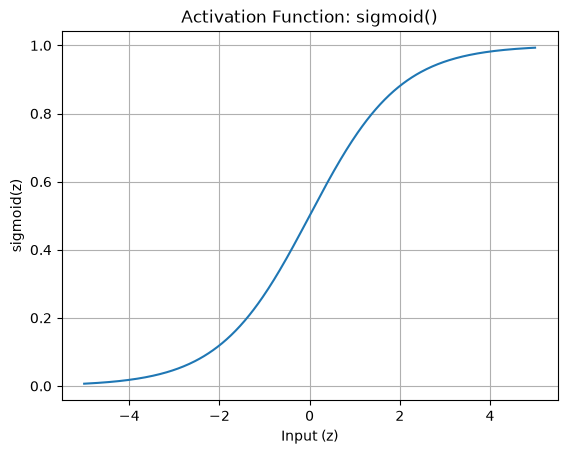

In [18]:
# compute sigmoid
sigmoid_values = 1 / (1 + np.exp(-z))

# create plot
plt.figure()
plt.plot(z, sigmoid_values)
plt.title("Activation Function: sigmoid()")
plt.xlabel("Input (z)")
plt.ylabel("sigmoid(z)")
# plt.axhline(0)
# plt.axvline(0)
plt.grid(True)

out_file_name = 'sigmoid_activation_function.png'
plt.savefig(out_file_name)

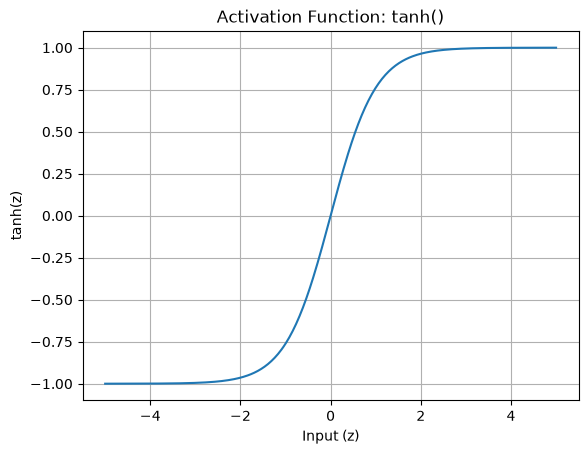

In [19]:
# compute tanh values
tanh_values = np.tanh(z)

# create plot
plt.figure()
plt.plot(z, tanh_values)
plt.title("Activation Function: tanh()")
plt.xlabel("Input (z)")
plt.ylabel("tanh(z)")
# plt.axhline(0)
# plt.axvline(0)
plt.grid(True)

out_file_name = 'tanh_activation_function.png'
plt.savefig(out_file_name)

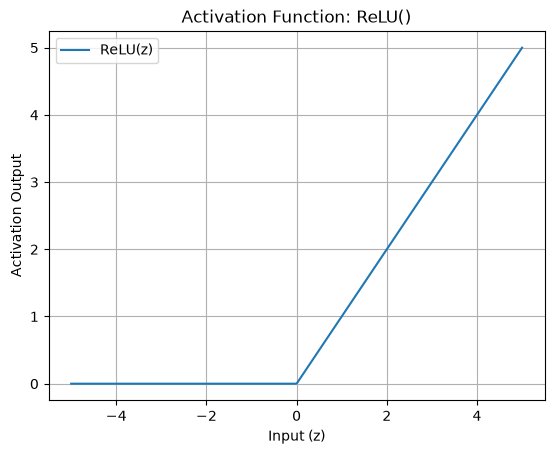

In [20]:
relu_values = np.maximum(0, z)

# plot
plt.figure()
# plt.plot(z, tanh_values, label="tanh(z)")
plt.plot(z, relu_values, label="ReLU(z)")
plt.title("Activation Function: ReLU()")
plt.xlabel("Input (z)")
plt.ylabel("Activation Output")
# plt.axhline(0)
# plt.axvline(0)
plt.legend()
plt.grid(True)

out_file_name = 'relu_activation_function.png'
plt.savefig(out_file_name)

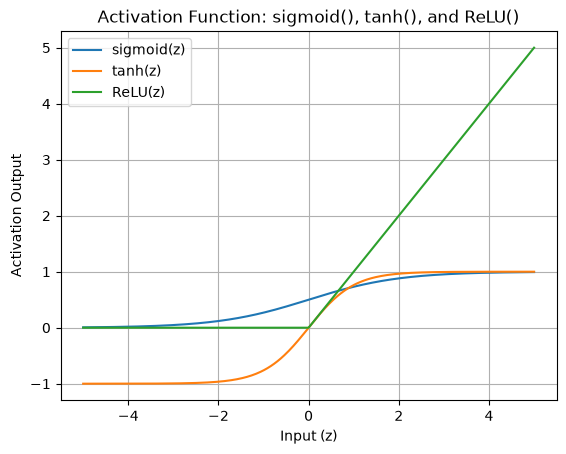

In [21]:
# put sigmoid, tanh, and relu together

plt.figure()
plt.plot(z, sigmoid_values, label="sigmoid(z)")
plt.plot(z, tanh_values, label="tanh(z)")
plt.plot(z, relu_values, label="ReLU(z)")
plt.title("Activation Function: sigmoid(), tanh(), and ReLU()")
plt.xlabel("Input (z)")
plt.ylabel("Activation Output")
# plt.axhline(0)
# plt.axvline(0)
plt.legend()
plt.grid(True)

out_file_name = 'sigmoid_tanh_relu_activation_function.png'
plt.savefig(out_file_name)

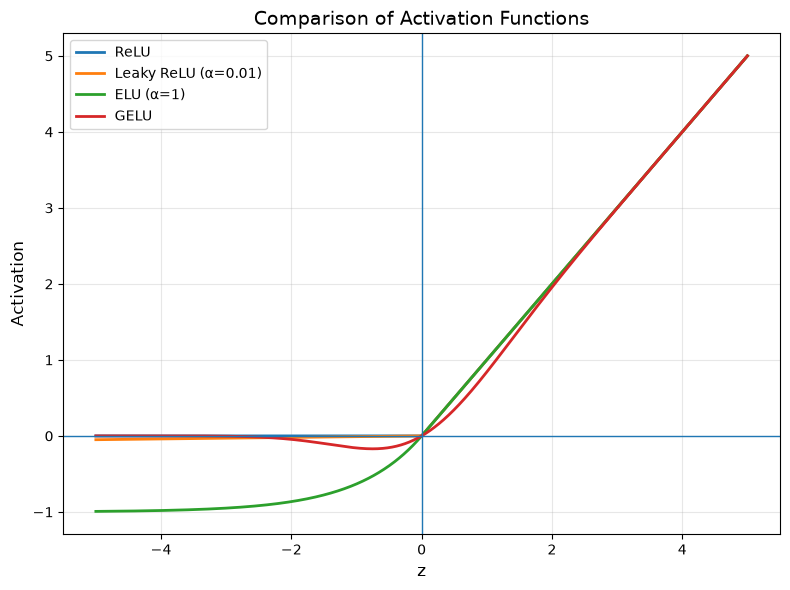

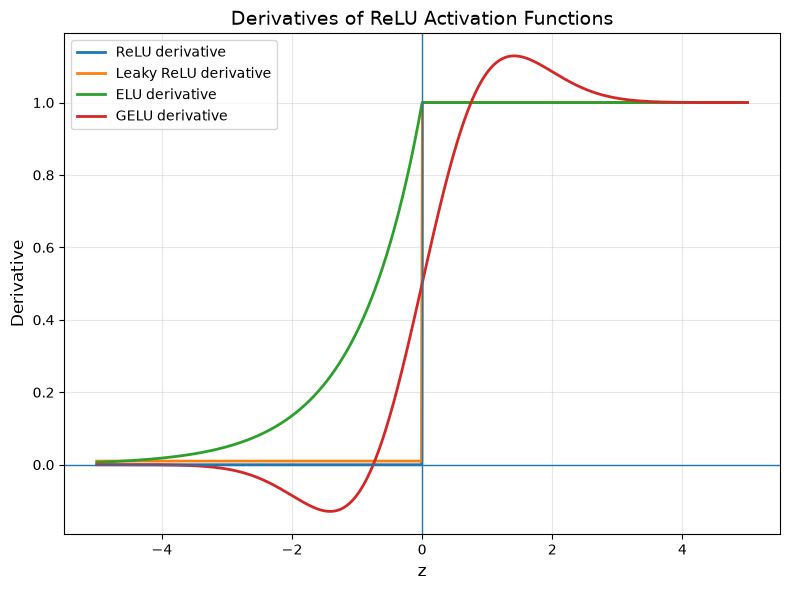

In [22]:
from scipy.special import erf

# Input range
z = np.linspace(-5, 5, 1000)

# -----------------------------
# Activation functions
# -----------------------------
def relu(z):
    return np.maximum(0, z)

def leaky_relu(z, alpha=0.01):
    return np.where(z > 0, z, alpha * z)

def elu(z, alpha=1.0):
    return np.where(z > 0, z, alpha * (np.exp(z) - 1))

def gelu(z):
    return 0.5 * z * (1 + erf(z / np.sqrt(2)))

# -----------------------------
# Derivatives
# -----------------------------
def d_relu(z):
    # Convention used in deep learning: derivative at z=0 set to 0
    return np.where(z > 0, 1.0, 0.0)

def d_leaky_relu(z, alpha=0.01):
    return np.where(z > 0, 1.0, alpha)

def d_elu(z, alpha=1.0):
    return np.where(z > 0, 1.0, alpha * np.exp(z))

def d_gelu(z):
    # Exact derivative of GELU:
    # GELU(z) = z * Phi(z)
    # d/dz = Phi(z) + z * phi(z)
    phi = (1 / np.sqrt(2 * np.pi)) * np.exp(-0.5 * z**2)
    Phi = 0.5 * (1 + erf(z / np.sqrt(2)))
    return Phi + z * phi

# Compute activations
relu_vals = relu(z)
leaky_vals = leaky_relu(z)
elu_vals = elu(z)
gelu_vals = gelu(z)

# Compute derivatives
d_relu_vals = d_relu(z)
d_leaky_vals = d_leaky_relu(z)
d_elu_vals = d_elu(z)
d_gelu_vals = d_gelu(z)

# -----------------------------
# Plot 1: Activation functions
# -----------------------------
plt.figure(figsize=(8, 6))
plt.plot(z, relu_vals, label='ReLU', linewidth=2)
plt.plot(z, leaky_vals, label='Leaky ReLU (α=0.01)', linewidth=2)
plt.plot(z, elu_vals, label='ELU (α=1)', linewidth=2)
plt.plot(z, gelu_vals, label='GELU', linewidth=2)

plt.axhline(0, linewidth=1)
plt.axvline(0, linewidth=1)

plt.xlabel('z', fontsize=12)
plt.ylabel('Activation', fontsize=12)
plt.title('Comparison of Activation Functions', fontsize=14)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

out_file_name = 'relu_activation_function and variations.png'
plt.savefig(out_file_name)
plt.show()

# -----------------------------
# Plot 2: Derivatives
# -----------------------------
plt.figure(figsize=(8, 6))
plt.plot(z, d_relu_vals, label='ReLU derivative', linewidth=2)
plt.plot(z, d_leaky_vals, label='Leaky ReLU derivative', linewidth=2)
plt.plot(z, d_elu_vals, label='ELU derivative', linewidth=2)
plt.plot(z, d_gelu_vals, label='GELU derivative', linewidth=2)

plt.axhline(0, linewidth=1)
plt.axvline(0, linewidth=1)

plt.xlabel('z', fontsize=12)
plt.ylabel('Derivative', fontsize=12)
plt.title('Derivatives of ReLU Activation Functions', fontsize=14)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
out_file_name = 'd_relu_activation_function.png'
plt.savefig(out_file_name)
plt.show()